> **ANEXO – Hipótesis inicial (solo variables de la ficha).** Continúa el `Anexo_Step4_solo_ficha`. El resultado negativo de este notebook **justificó el enfoque con mediciones** de los Steps 4–6.

# **Anexo Step 6 – Selección de algoritmos: viabilidad con solo la ficha**
**Proyecto TA – Análisis de Datos (1INF03, 2026-2) – Equipo E10**

> *KDD, paso 6:* «Choosing the data mining algorithms: which models and parameters may be appropriate for searching for patterns.»

**Pregunta:** ¿hay señal en las variables administrativas de la ficha para predecir la alteración nutricional? Se evalúan los tres modelos vistos en clase (regresión logística, KNN y SVC) frente a una línea base que siempre predice la clase mayoritaria.

**Reglas:**
- Solo se usa el **entrenamiento** (112 niños) con validación cruzada repetida (5 pliegues × 10 repeticiones); la prueba no se toca.
- Imputación, escalado, codificación y descarte de columnas van **dentro de un `Pipeline`**, así se reajustan en cada pliegue sin filtrar información del pliegue de validación.
- Se reportan AUC-ROC, exactitud balanceada y F1 macro, y una prueba de permutaciones.

Etiquetas: `alteracion_estricta` (principal) y `alteracion` (sensibilidad).

## Librerías y rutas

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import KNNImputer
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, permutation_test_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
TRA, RES, FIG = Path("../datos/3_transformados"), Path("../datos/4_resultados"), Path("../figuras")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110

## 1. Datos y decisiones del Anexo Step 4
Se lee el entrenamiento sin transformar y la lista de columnas que el Anexo Step 4 decidió descartar.

In [2]:
tr = pd.read_csv(TRA/"anexo4_train.csv", sep="|", index_col=0)
dec = json.load(open(TRA/"anexo4_decisiones.json", encoding="utf-8"))
targets = {"alteracion_estricta (principal)": tr["alteracion_estricta"], "alteracion (amplia)": tr["alteracion"]}
X = tr.drop(columns=["alteracion_estricta", "alteracion"])
for k, v in targets.items(): print(f"{k}: n = {len(v)}, % positivos = {100*v.mean():.1f}")
print("Predictores:", X.shape[1], "| columnas a descartar tras codificar:", len(dec["descartar_tras_codificar"]))

alteracion_estricta (principal): n = 112, % positivos = 40.2
alteracion (amplia): n = 112, % positivos = 68.8
Predictores: 19 | columnas a descartar tras codificar: 10


## 2. Pipeline de preprocesamiento
Se repiten, como pasos de un `Pipeline`, las transformaciones del Anexo Step 4: imputación (KNN para tiempo en el hogar, mediana para severidad), escalado robusto, *one-hot* y descarte de columnas. `seleccion` permite quedarse con un subconjunto para la ablación.

In [3]:
class Imputar(BaseEstimator, TransformerMixin):
    """KNN (k=5) para edad/tiempo en el hogar y mediana de severidad entre niños con discapacidad; se ajusta en el pliegue de entrenamiento."""
    def fit(self, X, y=None):
        self.knn_ = KNNImputer(n_neighbors=5).fit(X[["edad","tiempo_hogar_meses"]])
        self.med_ = X.loc[X["severidad_discapacidad"] > 0, "severidad_discapacidad"].median(); return self
    def transform(self, X):
        X = X.copy(); X[["edad","tiempo_hogar_meses"]] = self.knn_.transform(X[["edad","tiempo_hogar_meses"]])
        X["severidad_discapacidad"] = X["severidad_discapacidad"].fillna(self.med_); return X

def preproc(seleccion=None):
    ct = ColumnTransformer([("num", RobustScaler(), dec["num_cols"]),
                            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), dec["nominales"])],
                           remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
    quitar = FunctionTransformer(lambda Z: Z.drop(columns=[c for c in dec["descartar_tras_codificar"] if c in Z.columns]))
    pasos = [("imputar", Imputar()), ("codificar", ct), ("descartar", quitar)]
    if seleccion: pasos.append(("seleccion", FunctionTransformer(lambda Z: Z[[c for c in Z.columns if seleccion(c)]])))
    return pasos

def pipe(modelo, seleccion=None): return Pipeline(preproc(seleccion) + [("modelo", modelo)])
print("Columnas que salen del preprocesamiento:", pipe(DummyClassifier()).fit(X, targets["alteracion (amplia)"])[:-1].transform(X).shape[1])

Columnas que salen del preprocesamiento: 18


## 3. Comparación de modelos (validación cruzada 5 × 10)
Hiperparámetros fijos, iguales a los del enfoque principal. Para cada etiqueta y modelo se promedian las métricas de los 50 pliegues.

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=1)
modelos = {"Línea base (clase mayoritaria)": DummyClassifier(strategy="most_frequent"),
           "Regresión logística": LogisticRegression(class_weight="balanced", C=0.5, max_iter=2000),
           "KNN (k=9)": KNeighborsClassifier(n_neighbors=9),
           "SVC (kernel rbf)": SVC(kernel="rbf", C=1, class_weight="balanced")}
filas = []
for t, y in targets.items():
    for n, m in modelos.items():
        r = cross_validate(pipe(m), X, y, cv=cv, scoring=["accuracy","balanced_accuracy","f1_macro","roc_auc"])
        filas.append({"etiqueta": t, "modelo": n, "AUC": r["test_roc_auc"].mean(), "AUC (desv.)": r["test_roc_auc"].std(),
                      "exactitud balanceada": r["test_balanced_accuracy"].mean(), "F1 macro": r["test_f1_macro"].mean(), "exactitud": r["test_accuracy"].mean()})
res = pd.DataFrame(filas); res.to_csv(RES/"anexo6_comparacion.csv", sep="|", index=False); res.round(3)

,etiqueta,modelo,AUC,AUC (desv.),exactitud balanceada,F1 macro,exactitud
0,alteracion_estricta (principal),Línea base (clase mayoritaria),0.500,0.000,0.500,0.374,0.598
1,alteracion_estricta (principal),Regresión logística,0.558,0.109,0.539,0.529,0.543
2,alteracion_estricta (principal),KNN (k=9),0.478,0.108,0.502,0.480,0.556
3,alteracion_estricta (principal),SVC (kernel rbf),0.538,0.111,0.510,0.502,0.524
4,alteracion (amplia),Línea base (clase mayoritaria),0.500,0.000,0.500,0.407,0.687
5,alteracion (amplia),Regresión logística,0.505,0.119,0.499,0.480,0.515
6,alteracion (amplia),KNN (k=9),0.557,0.110,0.535,0.514,0.656
7,alteracion (amplia),SVC (kernel rbf),0.518,0.102,0.515,0.500,0.547


Se grafica el AUC de cada modelo frente al azar (0,5).

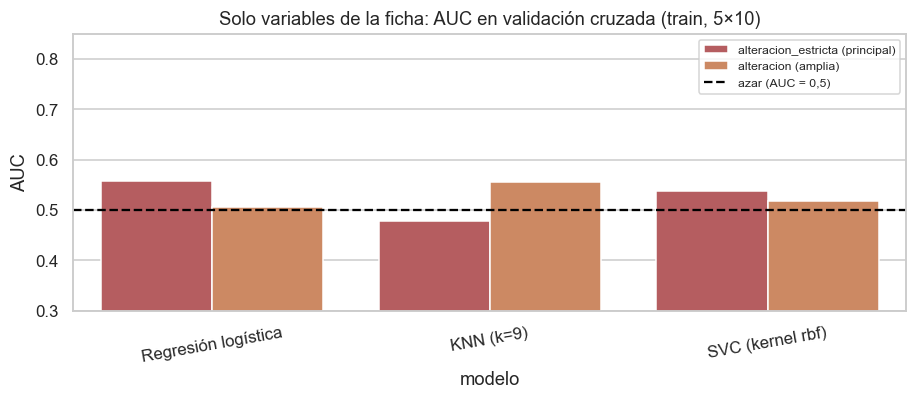

In [5]:
fig, ax = plt.subplots(figsize=(8.5,3.8))
sns.barplot(data=res[res["modelo"] != "Línea base (clase mayoritaria)"], x="modelo", y="AUC", hue="etiqueta", ax=ax, palette=["#C44E52","#DD8452"])
ax.axhline(0.5, color="black", ls="--", label="azar (AUC = 0,5)"); ax.set_ylim(0.3, 0.85); ax.legend(fontsize=8)
ax.set_title("Solo variables de la ficha: AUC en validación cruzada (train, 5×10)"); plt.xticks(rotation=10); plt.tight_layout()
plt.savefig(FIG/"anexo6_viabilidad_auc.png", bbox_inches="tight"); plt.show()

**Interpretación.** Con solo las variables de la ficha **ningún modelo se separa de la línea base**: el AUC va de 0,48 a 0,56 en ambas etiquetas, con una desviación entre pliegues de ≈0,11, mayor que cualquier diferencia entre modelos. La exactitud balanceada queda en 0,50–0,54, es decir, prácticamente al azar.

## 4. Prueba de permutaciones: ¿el AUC se distingue del azar?
Se barajan las etiquetas 200 veces y se recalcula el AUC (validación 5 × 2). Si el AUC real no supera a la mayoría de los barajados, el modelo no encontró señal.

In [6]:
perm = []
for t, y in targets.items():
    for n in ["Regresión logística", "SVC (kernel rbf)"]:
        s, perms, p = permutation_test_score(pipe(modelos[n]), X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=1),
                                             scoring="roc_auc", n_permutations=200, random_state=1, n_jobs=1)
        perm.append({"etiqueta": t, "modelo": n, "AUC real": round(s,3), "AUC medio barajado": round(perms.mean(),3),
                     "percentil 95 barajado": round(np.percentile(perms, 95),3), "p-valor": round(p,3)})
perm = pd.DataFrame(perm); perm.to_csv(RES/"anexo6_permutaciones.csv", sep="|", index=False); perm

,etiqueta,modelo,AUC real,AUC medio barajado,percentil 95 barajado,p-valor
0,alteracion_estricta (principal),Regresión logística,0.556,0.492,0.602,0.204
1,alteracion_estricta (principal),SVC (kernel rbf),0.520,0.493,0.600,0.353
2,alteracion (amplia),Regresión logística,0.531,0.492,0.618,0.373
3,alteracion (amplia),SVC (kernel rbf),0.550,0.494,0.632,0.289


**Interpretación.** El AUC real **no se distingue del obtenido con etiquetas barajadas**: en los cuatro casos queda por debajo del percentil 95 de las permutaciones y el *p*-valor va de 0,20 a 0,37. No hay evidencia de señal.

## 5. ¿Cuánto aporta la edad? (ablación)
Se repite la regresión logística con la edad sola, con todo menos la edad y con todas las variables.

In [7]:
bloques = {"solo edad": lambda c: c == "edad", "todo menos edad": lambda c: c != "edad", "todas": None}
filas = []
for t, y in targets.items():
    for b, sel in bloques.items():
        r = cross_validate(pipe(modelos["Regresión logística"], sel), X, y, cv=cv, scoring=["roc_auc","balanced_accuracy"])
        filas.append({"etiqueta": t, "variables": b, "AUC": round(r["test_roc_auc"].mean(),3), "exactitud balanceada": round(r["test_balanced_accuracy"].mean(),3)})
abl = pd.DataFrame(filas); abl.to_csv(RES/"anexo6_ablacion.csv", sep="|", index=False); abl

,etiqueta,variables,AUC,exactitud balanceada
0,alteracion_estricta (principal),solo edad,0.623,0.616
1,alteracion_estricta (principal),todo menos edad,0.503,0.508
2,alteracion_estricta (principal),todas,0.558,0.539
3,alteracion (amplia),solo edad,0.561,0.576
4,alteracion (amplia),todo menos edad,0.489,0.488
5,alteracion (amplia),todas,0.505,0.499


**Interpretación.** La **edad sola rinde mejor que todas las variables** (AUC 0,62 frente a 0,56 con la etiqueta estricta; 0,56 frente a 0,51 con la amplia), y "todo menos edad" queda en el azar (≈0,50). Las variables administrativas **añaden ruido**, no información.

## 6. Conclusiones de la prueba de viabilidad

1. **Con las variables de la ficha no se puede predecir la alteración nutricional.** Ningún modelo supera a la línea base (AUC 0,48–0,56) y la prueba de permutaciones no distingue el resultado del azar (*p* ≥ 0,20).
2. **La única señal es la edad** (AUC 0,62 sola, con la etiqueta estricta), coherente con el Step 2b: la alteración es más frecuente en los mayores.
3. **Lectura para el negocio:** situación legal, UPE, educación, soporte psicológico o discapacidad no identifican a los NNA con alteración. Los factores relevantes (alimentación, salud previa al ingreso, **mediciones**) no están en la ficha. Esto motivó el enfoque principal: usar peso, talla e IMC del Bloque 2 (Steps 4–6).

**Limitaciones.** Pocos niños (112 en entrenamiento), alta variabilidad entre pliegues (desv. del AUC ≈ 0,11) y un único registro por niño. El conjunto de prueba (38 niños) no se usó. El resultado se presenta tal cual: es un hallazgo, y ajustar el modelo hasta que "funcione" sería sobreajustar al ruido.

## Verificación y cifras de este notebook

In [8]:
r = res.set_index(["etiqueta", "modelo"])["AUC"]
assert r.drop(index="Línea base (clase mayoritaria)", level=1).between(0.47, 0.565).all()
assert (perm["p-valor"] >= 0.2).all() and (perm["AUC real"] < perm["percentil 95 barajado"]).all()
a = abl.set_index(["etiqueta", "variables"])["AUC"]
assert round(a[("alteracion_estricta (principal)", "solo edad")], 2) == 0.62 and a[("alteracion_estricta (principal)", "solo edad")] > a[("alteracion_estricta (principal)", "todas")]
cifras = {"auc_max_modelos": round(float(r.drop(index="Línea base (clase mayoritaria)", level=1).max()), 3),
          "p_min_permutaciones": float(perm["p-valor"].min()), "auc_solo_edad_estricta": float(a[("alteracion_estricta (principal)", "solo edad")])}
cifras.update({"auc_min_modelos": round(float(r.drop(index="Línea base (clase mayoritaria)", level=1).min()), 3), "p_max_permutaciones": float(perm["p-valor"].max()),
               "auc_todas_estricta": float(a[("alteracion_estricta (principal)", "todas")])})
json.dump(cifras, open(RES/"cifras_anexo6.json", "w"), indent=1); cifras

{'auc_max_modelos': 0.558,
 'p_min_permutaciones': 0.204,
 'auc_solo_edad_estricta': 0.623,
 'auc_min_modelos': 0.478,
 'p_max_permutaciones': 0.373,
 'auc_todas_estricta': 0.558}